# Chicago traffic assignment

Use AequilibraE 2.0 to find a shortest path, assign morning peak demand, and compare how three groups of drivers respond to different link costs.

## Open the Chicago model

Run this notebook with AequilibraE 2.0. The workshop model lives in `data/chicago_sample_model`, relative to this notebook. The project database (`project_database.sqlite`) holds the network and zone tables. The `matrices/` folder holds travel demand by time of day in Open Matrix (OMX) files.

Run the cells in order. Each `with Project.open(...)` block opens the project for the work in that cell and closes it at the end of the block.

In [1]:
import logging
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from aequilibrae import Project
from aequilibrae.matrix import from_dict
from aequilibrae.routing import Network
from aequilibrae.traffic import VDF, TrafficAssignment, TrafficClass
from aequilibrae.traffic.vdf import bpr
from aequilibrae.utils import basic_config
from chicago_traffic_visualisation import show_link_results
from IPython.display import display
from shapely.geometry import Point

basic_config(level=logging.INFO)


<AequilibraETQDMStreamHandler stdout (NOTSET)>

### Read the project tables

Use `project.tables.<table>.data` to read each table into a DataFrame. The links, nodes and zones also have a `geometry` column that we can use for maps.

- **Links** are roads and centroid connectors. Each row has a `link_id` and two endpoint IDs, `a_node` and `b_node`. The `direction` field uses `1` for A to B, `-1` for B to A and `0` for both directions.
- **Nodes** are the link endpoints. A node with `is_centroid = 1` is where trips for a zone start or end on the network. Centroid connectors join these nodes to the road network.
- **Zones** are the areas that trips start from or end in. In this model, each `zone_id` matches the `node_id` of its centroid.
- **Modes** gives the name and code for each travel mode. Chicago uses `c` for all motorised vehicles, including trucks.

This is purely for data exploration. When requested, AequilibraE will read all the required information automatically.

In [2]:
model_path = Path.cwd() / "data" / "chicago_sample_model"

with Project.open(model_path) as project:
    links = project.tables.links.data
    nodes = project.tables.nodes.data
    zones = project.tables.zones.data
    modes = project.tables.modes.data

print("Links")
display(
    links[["link_id", "a_node", "b_node", "direction", "modes", "link_type"]].head()
)

print("Nodes")
node_columns = ["node_id", "is_centroid", "geometry"]
display(nodes[node_columns].head(3))
display(nodes.loc[nodes["is_centroid"] == 1, node_columns].head(3))

print("Zones")
display(zones[["zone_id", "geometry"]].head(3))

print("Modes")
display(modes)

2026-11-20 22:13:57,430;INFO ; Opened project on D:\OL\src\atrf2026\workshop\data\chicago_sample_model
2026-11-20 22:13:57,818;INFO ; Closed project on D:\OL\src\atrf2026\workshop\data\chicago_sample_model
Links


,link_id,a_node,b_node,direction,modes,link_type
0,1792,14791,23462,1,c,default
1,1793,14791,23463,1,c,default
2,1794,14791,25973,1,c,default
3,1795,14792,14821,1,c,default
4,1796,14792,17238,1,c,default


Nodes


,node_id,is_centroid,geometry
0,14791,0,POINT (-87.62495 41.60049)
1,14792,0,POINT (-88.28207 41.78472)
2,14793,0,POINT (-87.61727 41.62251)


,node_id,is_centroid,geometry
11189,1,1,POINT (-87.87354 41.12948)
11190,2,1,POINT (-87.87646 41.13978)
11191,3,1,POINT (-88.22967 42.44077)


Zones


,zone_id,geometry
0,1,"MULTIPOLYGON (((-87.88768 41.13594, -87.88764 ..."
1,2,"MULTIPOLYGON (((-87.8941 41.14388, -87.894 41...."
2,3,"MULTIPOLYGON (((-88.27677 42.41889, -88.27677 ..."


Modes


,mode_name,mode_id,description
0,car,c,All motorized vehicles


### Build the road network

Use `project.road.build_network()` to turn the project tables into a routing `Network`. Pass `modes=["c"]` to include links that allow motorised vehicles. The network includes the link IDs, endpoints, allowed directions and centroid IDs needed for routing.

Use `fields` to bring in the extra columns needed for this workshop. `free_flow_time` is travel time without congestion. `capacity` loads both `capacity_ab` and `capacity_ba`. The `b` and `power` fields control how travel time rises with congestion in the assignment.

The network stays in memory after the project closes. Later we will build a graph from it by choosing a mode and a routing cost.

In [3]:
with Project.open(model_path) as project:
    network = project.road.build_network(
        fields=["free_flow_time", "capacity", "b", "power"], modes=["c"]
    )

print(network)
network.links[
    ["link_id", "free_flow_time", "capacity_ab", "capacity_ba", "b", "power"]
].head()

2026-11-20 22:13:58,102;INFO ; Opened project on D:\OL\src\atrf2026\workshop\data\chicago_sample_model
2026-11-20 22:13:58,256;INFO ; Closed project on D:\OL\src\atrf2026\workshop\data\chicago_sample_model
Network:
  Links: 37742 physical, 40048 directed
  Nodes: 13495, centroids: 2306
  Modes: ('c',), turn restrictions: 0
  Lon/lat nodes: 13495, allow U-turns: False


,link_id,free_flow_time,capacity_ab,capacity_ba,b,power
0,1792,1.272,720.0,NaN,0.15,4
1,1793,0.703,1728.0,NaN,0.15,4
2,1794,0.429,1728.0,NaN,0.15,4
3,1795,0.900,924.0,NaN,0.15,4
4,1796,0.255,1944.0,NaN,0.15,4


### Find the demand files

Use `project.matrices.list()` to see the OMX files and their stored descriptions. Each file can hold several named matrices. We will use `am.omx`, which contains hourly average trips for the morning peak from 7 to 9 am.

In [4]:
with Project.open(model_path) as project:
    matrix_files = project.matrices.list()

matrix_files[["description"]]

2026-11-20 22:13:58,324;INFO ; Opened project on D:\OL\src\atrf2026\workshop\data\chicago_sample_model
2026-11-20 22:13:58,347;INFO ; Closed project on D:\OL\src\atrf2026\workshop\data\chicago_sample_model


,description
file_name,
am.omx,AM Peak: 7 to 9AM
md.omx,MD Period: 9AM to 4PM
op.omx,Off-Peak Period: 7PM to 6AM
pm.omx,PM Peak: 4PM to 7AM


### Inspect and select matrices

An origin–destination (OD) matrix has one row per origin zone and one column per destination zone. Both axes use the same zone IDs in the same order. Use `.index` to access these IDs and `index_name` to see the name of the zone mapping in the OMX file.

AequilibraE has three main matrix types, the ``MatrixStore`` for on disk operations, including lazy loading and file management. ``AequilibraeMatrix`` (and it's sparse equivalent ``AequilibraeSparseMatrix``) for in memory operations. These objects behave like dictionaries with some additional methods for convenient usage.

| Object | Where the values live | How to read them |
| --- | --- | --- |
| `MatrixStore` | In an open OMX file. `get_matrix("am.omx")` opens it read-only by default. | List the matrix names with `list(am_store)`. Read a whole matrix with `am_store["car"]` or use `am_store.imat` to read just a slice by position. Use the store inside its `with` block. |
| `AequilibraeMatrix` | In memory as dense NumPy arrays. | Read a whole matrix with `demand["car"]` or use `demand.mat` to look up values by zone ID. The object can be used after the file and project close. |
| `AequilibraeSparseMatrix` | In memory as sparse SciPy arrays. | Read a whole matrix with `demand["car"]` or use `demand.mat` to look up values by zone ID. The object can be used after the file and project close. |

Both objects support `mat` for zone IDs and `imat` for zero-based array positions. With a `MatrixStore`, reading values loads them from disk. With an `AequilibraeMatrix`, editing an array returned by `demand["car"]` changes the in-memory object. Saving those changes to OMX takes a separate export.

`am_store.subset(demand_names)` copies the named matrices and their zone index into memory. Here it loads cars, heavy trucks and medium trucks and keeps every zone for each matrix. You can also pass dictionaries to select matrices by their metadata. Use `imat` or `mat` when you want particular rows and columns.

If you already know which matrices you want, `project.matrices.get_matrix("am.omx", subset=demand_names)` loads the same selection directly.

In [5]:
demand_names = ["car", "heavy_trucks", "medium_trucks"]

with (
    Project.open(model_path) as project,
    project.matrices.get_matrix("am.omx") as am_store,
):
    print(f"{type(am_store).__name__} matrices: {list(am_store)}")
    print(f"Zone mapping: {am_store.index_name}, matrix shape: {am_store.shape}")

    # Preview the car matrix at positions 2 to 6 on both axes.
    preview_zones = am_store.index[2:7]
    car_preview = pd.DataFrame(
        am_store.imat["car", 2:7, 2:7],
        index=pd.Index(preview_zones, name="Origin"),
        columns=pd.Index(preview_zones, name="Destination"),
    )
    display(car_preview)

    demand = am_store.subset(demand_names)

print(f"{type(demand).__name__} matrices: {list(demand)}")

2026-11-20 22:13:58,880;INFO ; Opened project on D:\OL\src\atrf2026\workshop\data\chicago_sample_model
MatrixStore matrices: ['car', 'heavy_trucks', 'medium_trucks', 'transit', 'uber']
Zone mapping: taz, matrix shape: (2306, 2306)


Destination,3,4,5,6,7
Origin,,,,,
3,214.0,0.0,0.0,4.0,0.0
4,0.0,172.0,8.0,2.0,4.0
5,0.0,6.0,10.0,0.0,6.0
6,6.0,4.0,0.0,108.0,0.0
7,0.0,2.0,2.0,0.0,6.0


2026-11-20 22:13:59,083;INFO ; Closed project on D:\OL\src\atrf2026\workshop\data\chicago_sample_model
AequilibraeMatrix matrices: ['car', 'heavy_trucks', 'medium_trucks']


Use `demand.mat["car", 4, 5]` to read the trip rate from zone 4 to zone 5. You can find the same value in the preview above. Use `demand["car"]` to get the full car matrix as a NumPy array. Sum each array to get the total hourly trips for that vehicle type.

In [6]:
car_trips = demand["car"]
print(f"Car matrix: {type(car_trips).__name__}, shape {car_trips.shape}")
print(f"Car trips per hour from zone 4 to zone 5: {demand.mat['car', 4, 5]:g}")
pd.Series({name: demand[name].sum() for name in demand}, name="Hourly trips")

Car matrix: ndarray, shape (2306, 2306)
Car trips per hour from zone 4 to zone 5: 8


car              2001848.0
heavy_trucks       28528.0
medium_trucks     125350.0
Name: Hourly trips, dtype: float64

## Find a shortest path

Build a graph for road mode `c` using free-flow travel time. Read the physical link IDs and directions in the order travelled from zone 1 to zone 8. A direction of 1 follows the link from A to B, and −1 goes from B to A.

In [7]:
graph = network.build_graph("c", cost="free_flow_time")
path = graph.compute_path(1, 8)
link_ids, directions = path.get_network_links()

pd.DataFrame({"link_id": link_ids, "direction": directions}).head(10)

,link_id,direction
0,39019,1
1,28040,1
2,28060,1
3,28103,1
4,28106,1
5,28108,1
6,28149,1
7,28083,1
8,28016,1
9,17359,1


## Choose a volume–delay function

The BPR function gives the travel time on a link as `free_flow_time × (1 + alpha × (flow / capacity)^beta)`. All three versions read `alpha` from the network's `b` field and `beta` from its `power` field.

The NumPy version uses Python functions that write into arrays supplied by AequilibraE. The NumExpr version passes expressions that AequilibraE evaluates. The derivative of travel time with respect to flow if optional, if not provided a finite difference will be used.

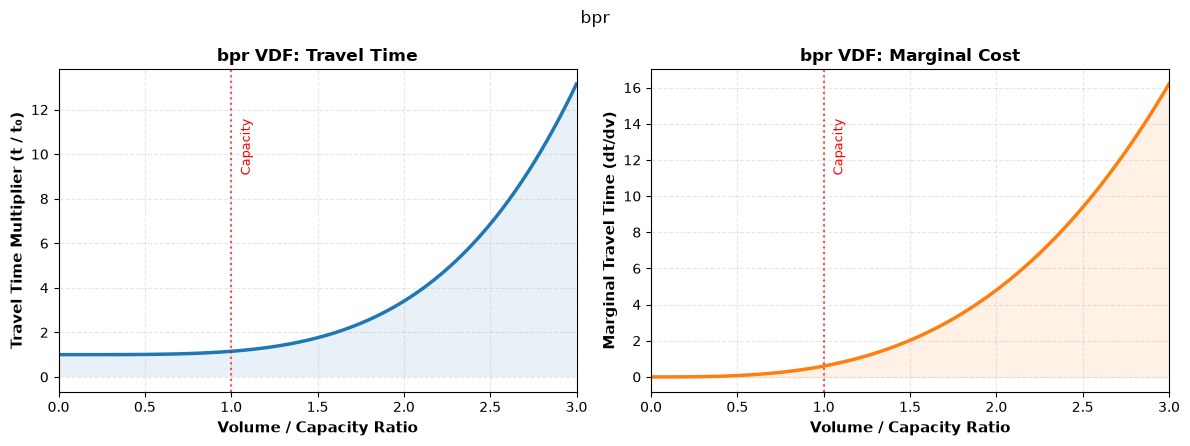

In [8]:
def bpr_numpy_time(out, link_flows, fftime, capacity, cores, *, alpha, beta):
    # Arbitrary VDF function using NumPy
    volume_ratio = link_flows / capacity
    out[:] = fftime * (1 + alpha * np.power(volume_ratio, beta))


def bpr_numpy_derivative(out, link_flows, fftime, capacity, cores, *, alpha, beta):
    volume_ratio = link_flows / capacity
    out[:] = fftime * alpha * beta / capacity * np.power(volume_ratio, beta - 1)


bpr_numpy = VDF(
    name="BPR NumPy",
    function=bpr_numpy_time,
    derivative=bpr_numpy_derivative,
    spec=bpr.spec,
)

bpr_numexpr = VDF(
    name="BPR NumExpr",
    function="fftime * (1 + alpha * (link_flows / capacity) ** beta)",
    # The derivative is option, if not provided then a finite difference will be used.
    # derivative="fftime * alpha * beta / capacity * (link_flows / capacity) ** (beta - 1)",
    spec=bpr.spec,
)


def show_vdf(vdf):
    num_points = 100
    link_attributes = {
        "alpha": np.full(num_points, 0.15),
        "beta": np.full(num_points, 4.0),
    }
    vdf.plot_vdf(num_points=num_points, link_attributes=link_attributes)


vdf = bpr
# vdf = bpr_numpy
# vdf = bpr_numexpr

show_vdf(vdf)

## Assign morning peak demand

The AM matrices contain hourly average trips for the morning peak. Cars, heavy trucks and medium trucks share a single traffic class here. They use the same mode, routing costs and passenger car equivalent (PCE) factor of 1.

The assignment builds the class graph and uses the selected BPR function. The ten-iteration limit keeps the run short. Check the reported relative gap (`rgap`) to see how close it came to the target.

In [9]:
road_class = TrafficClass(name="road", mode="c", cost="free_flow_time", demand=demand)

assignment = TrafficAssignment(
    network=network,
    classes=[road_class],
    time_field="free_flow_time",
    capacity_field="capacity",
    vdf=vdf,
    name_mapping={"alpha": "b", "beta": "power"},
    algorithm="bfw",
)

results = assignment.execute(max_iterations=10, rgap=1e-6, cores=4)

2026-11-20 22:13:59,821;INFO ; Traffic Class specification
2026-11-20 22:13:59,842;INFO ; {'network mode': 'c', 'cost': 'free_flow_time', 'PCE': 1.0, 'Value-of-time': 1.0, 'Fixed cost field': None, 'Fixed cost multiplier': 1.0, 'matrix_totals': {'car': 2001848.0, 'heavy_trucks': 28528.0, 'medium_trucks': 125350.0}}
2026-11-20 22:13:59,843;INFO ; Traffic Assignment specification
2026-11-20 22:13:59,844;INFO ; {'Algorithm': 'bfw', 'Time field': 'free_flow_time', 'Capacity field': 'capacity', 'VDF function': 'bpr', 'VDF parameters': {'alpha': 'b', 'beta': 'power'}, 'Maximum iterations': 10, 'Target RGAP': 1e-06, 'BFW conjugacy': 'approximate', 'Number of cores': 4}
2026-11-20 22:14:00,182;INFO ; bfw Assignment stats
2026-11-20 22:14:00,183;INFO ; Iteration, RelativeGap (AoN), stepsize


Equilibrium Assignment                            :   0%|          | 0/10 [00:00<?, ?it/s]

2026-11-20 22:14:00,569;INFO ; 1,inf,1.0
2026-11-20 22:14:00,942;INFO ; 2,0.8962549759236212,0.23677608502221884
2026-11-20 22:14:01,311;INFO ; 3,0.7388651136369738,0.2053045819431779
2026-11-20 22:14:01,761;INFO ; 4,0.49619352453420995,0.22810671365229596
2026-11-20 22:14:02,215;INFO ; 5,0.2631396652388167,0.0869122877217915
2026-11-20 22:14:02,657;INFO ; 6,0.20036193014115158,0.21469959557877386
2026-11-20 22:14:03,089;INFO ; 7,0.19927750259103305,0.14770616723443455
2026-11-20 22:14:03,511;INFO ; 8,0.08383846176268228,0.060442682109012213
2026-11-20 22:14:03,918;INFO ; 9,0.09184932513795015,0.24257622350133673
2026-11-20 22:14:04,385;INFO ; 10,0.05278329061769422,nan
2026-11-20 22:14:04,386;ERROR ; Desired RGap of 1e-06 was NOT reached
2026-11-20 22:14:04,386;INFO ; bfw Assignment finished. 10 iterations, final AoN rgap = 0.05278329061769422


In [10]:
assignment.description = "Chicago morning peak traffic assignment"
am_table = f"chicago_am_{assignment.procedure_id}"

with Project.open(model_path) as project:
    assignment.save_results(am_table, project=project)
    saved_results = project.results.list()[["table_name", "procedure"]]

print(f"Saved {am_table} to results_database.sqlite.")
results[
    ["car_tot", "medium_trucks_tot", "heavy_trucks_tot", "PCE_tot", "VOC_max"]
].head()

2026-11-20 22:14:04,555;INFO ; Opened project on D:\OL\src\atrf2026\workshop\data\chicago_sample_model
2026-11-20 22:14:04,693;INFO ; Closed project on D:\OL\src\atrf2026\workshop\data\chicago_sample_model
Saved chicago_am_cea39640bfe34fdf920401d53de407dd to results_database.sqlite.


,car_tot,medium_trucks_tot,heavy_trucks_tot,PCE_tot,VOC_max
link_id,,,,,
1792,555.980891,22.227356,0.260541,578.468787,0.803429
1793,1252.950986,55.224752,6.000000,1314.175738,0.760518
1794,994.131028,51.101855,3.620080,1048.852963,0.606975
1795,1184.259153,54.801798,22.407230,1261.468182,1.365225
1796,1039.985797,66.086996,18.203470,1124.276264,0.578331


### Read the results

The assignment returns one row per physical link, indexed by `link_id`. Load columns use the demand matrix name with `_ab`, `_ba` or `_tot`. The shared results include total PCE flow (`PCE_tot`) and the maximum directional volume-to-capacity ratio (`VOC_max`). Each run saves a new table in the project's `results_database.sqlite`. The table name includes the assignment's procedure ID.

In [11]:
display(assignment.report()[["iteration", "rgap", "alpha"]])
display(saved_results)

road_loads = assignment.class_results["road"].get_load_results()
road_loads.head()

,iteration,rgap,alpha
0,1,inf,1.000000
1,2,0.896255,0.236776
2,3,0.738865,0.205305
3,4,0.496194,0.228107
4,5,0.263140,0.086912
5,6,0.200362,0.214700
6,7,0.199278,0.147706
7,8,0.083838,0.060443
8,9,0.091849,0.242576
9,10,0.052783,NaN


,table_name,procedure
0,chicago_am_cea39640bfe34fdf920401d53de407dd,traffic assignment


,car_ab,car_ba,car_tot,heavy_trucks_ab,heavy_trucks_ba,heavy_trucks_tot,medium_trucks_ab,medium_trucks_ba,medium_trucks_tot
1792,555.980891,0.0,555.980891,0.260541,0.0,0.260541,22.227356,0.0,22.227356
1793,1252.950986,0.0,1252.950986,6.000000,0.0,6.000000,55.224752,0.0,55.224752
1794,994.131028,0.0,994.131028,3.620080,0.0,3.620080,51.101855,0.0,51.101855
1795,1184.259153,0.0,1184.259153,22.407230,0.0,22.407230,54.801798,0.0,54.801798
1796,1039.985797,0.0,1039.985797,18.203470,0.0,18.203470,66.086996,0.0,66.086996


### Map flows and congestion

Colours show the volume-to-capacity ratio (VoC) on both maps. On the first map, colour shows the higher ratio of the two directions and line width shows hourly volume. Use **Volume** to switch between all traffic and each vehicle type. The width scale stays the same across choices.

The maps and controls are in [chicago_traffic_visualisation.py](chicago_traffic_visualisation.py).

In [ ]:
show_link_results(
    links,
    results,
    zones,
    volume_options={
        "All traffic (PCE/h)": "PCE_tot",
        "Cars (veh/h)": "car_tot",
        "Medium trucks (veh/h)": "medium_trucks_tot",
        "Heavy trucks (veh/h)": "heavy_trucks_tot",
    },
)

## Multiclass traffic assignment

To create three separate classes we split the car demand evenly and modify their values of time to simulate a distance-based congestion charging area.

Each class faces a different toll within the links near central Chicago, varying from 0.1 to 0.2/km.

In [ ]:
from geopandas import GeoSeries

# Create a charging area, this can of course be any polygon
charge_area = (
    GeoSeries([Point(-87.63019, 41.81387)], crs="EPSG:4326")
    .to_crs("EPSG:32616")
    .buffer(10_000)
    .to_crs("EPSG:4326")
    .iloc[0]
)

affected_links = links.loc[
    links.geometry.within(charge_area) & (links["link_type"] != "centroid_connector"),
    "link_id",
]

We'll assign a fixed cost of ``1.0`` to these links, we could assign an actual value then use multiple different columns for the different traffic classes, but changing the multiplier will suffice.

In [ ]:
network.links.loc[:, "area_charge1"] = network.links.distance/1000  * 0.1
network.links.loc[:, "area_charge2"] = network.links.distance/1000  * 0.12
network.links.loc[:, "area_charge3"] = network.links.distance/1000  * 0.2

In [ ]:
# Value-of-time is in $/minute
vot = {"low": [15/60, "area_charge1"], "medium": [25/60, "area_charge2"], "high": [60/60, "area_charge3"]}
demand_per_class = demand["car"] / len(vot)

classes = [
    TrafficClass(
        name=name,
        mode="c",
        cost="free_flow_time",
        demand=from_dict(
            {name: demand_per_class}, index=demand.index, index_name=demand.index_name
        ),
        fixed_cost_field=vot[name][1],
        fc_multiplier=1.0, # We use the multiplier if we want to make a fixed conversion to the fixed cost
        vot=vot[name][0],
    )
    for name in vot.keys()
]

In [ ]:
multi_assignment = TrafficAssignment(
    network=network,
    classes=classes,
    time_field="free_flow_time",
    capacity_field="capacity",
    vdf=vdf,
    name_mapping={"alpha": "b", "beta": "power"},
    algorithm="bfw",
)

multi_results = multi_assignment.execute(max_iterations=10, rgap=1e-6, cores=4)

multi_assignment.description = (
    "Chicago morning peak car assignment with three fixed penalties"
)
charge_table = f"chicago_am_penalties_{multi_assignment.procedure_id}"

with Project.open(model_path) as project:
    multi_assignment.save_results(charge_table, project=project)

print(f"Saved {charge_table} to results_database.sqlite.")
display(multi_assignment.report()[["iteration", "rgap", "alpha"]])
multi_results[["low_tot", "medium_tot", "high_tot"]].head()

The orange circle marks the congestion charging area. Switch between the three classes to see its impact. Line width shows volume for the class you choose. Colour shows the higher directional VoC across all three classes, which share road capacity.

In [ ]:
show_link_results(
    links,
    multi_results,
    zones,
    volume_options={
        "Low charge (veh/h)": "low_tot",
        "Medium charge (veh/h)": "medium_tot",
        "High charge (veh/h)": "high_tot",
    },
    cordon=charge_area,
)